## Evaluación Parcial N°2 Machine Learning 002_D


#Caso Telco (Empresa de Telecomunicaciones)


Integrantes: Alfredo Álvarez

Diego Bustamante

Seccion: Machine Learning_002D


# Descripción del problema de negocio


El problema del negocio a analizar consiste en que los clientes de una empresa de telecomunicaciones que presta servicios de internet, TV y telefonía están abandonando la empresa y dando de baja sus servicios de forma notoria, lo que implica pérdidas de ingresos para el negocio.

A partir de los datos disponibles se busca comprender qué características se relacionan con el abandono y construir una solución de Machine Learning que permita detectar clientes con mayor riesgo de fuga y apoyar decisiones de retención.


# Objetivos del proyecto


* Identificar la demografía y características de los clientes que están abandonando.
* Analizar qué variables influyen más en la fuga de clientes.
* Preparar los datos para que puedan ser utilizados correctamente en modelos de Machine Learning.
* Construir y comparar modelos supervisados para predecir el abandono de clientes.
* Aplicar una técnica no supervisada para descubrir segmentos o patrones relevantes entre los clientes.
* Traducir los resultados obtenidos en información útil para apoyar estrategias de retención.


# Definición de KPIs que resolverán el problema de negocio


### KPI 1 Tasa de abandono (Churn Rate)

Nos permite medir el porcentaje general de clientes que dejan de utilizar los servicios y abandonan la empresa. Este indicador entrega una visión directa del nivel de pérdida de clientes que presenta el negocio.

### KPI 2 Churn clientes nuevos (0 a 6 meses)

Permite medir el porcentaje de clientes con hasta 6 meses de antigüedad que abandonan. Ayuda a determinar si los primeros meses de relación con la empresa representan un período de mayor riesgo.

### KPI 3 Churn por tipo de contrato (M/M, 1Y, 2Y)

Permite comparar la tasa de abandono según el tipo de contrato y conocer qué modalidad presenta una mayor pérdida de clientes. Esta información puede apoyar decisiones comerciales orientadas a la fidelización.

### KPI 4 Recall

Recall o exhaustividad permite medir qué porcentaje de los clientes que realmente abandonan fue detectado correctamente por el modelo. Se prioriza esta métrica porque un falso negativo representa un cliente que abandona sin haber sido identificado previamente como cliente en riesgo.


# Descripción de las fuentes de datos utilizadas


La fuente de los datos fue habilitada mediante el campus virtual de Duoc UC y corresponde al siguiente archivo:

```text
Telco_Customer_Churn_Dataset.csv
```

El archivo contiene información demográfica, contractual, de servicios y facturación de clientes de una empresa de telecomunicaciones. Será importado en Jupyter/Colab mediante la librería `pandas` como un DataFrame para permitir su exploración, preparación y posterior modelamiento.


## Herramientas utilizadas y justificación

| Herramienta | Uso en el proyecto | Justificación |
|-|-|-|
| Google Colab / Jupyter | Desarrollo y ejecución del notebook | Permite trabajar con Python en un entorno reproducible y ejecutar todas las etapas del análisis sin depender de una instalación local específica. |
| GitHub | Control de versiones y respaldo del proyecto | Permite mantener trazabilidad de los cambios, organizar la entrega y conservar versiones anteriores del trabajo. |
| pandas | Manipulación y preparación de datos | Facilita la carga, limpieza, transformación y análisis de datos tabulares. |
| matplotlib y seaborn | Visualización de datos | Permiten construir gráficos estadísticos para identificar distribuciones, relaciones y patrones relevantes para el negocio. |
| scikit-learn | Modelamiento y evaluación | Se utilizará para preparar variables, entrenar modelos de Machine Learning y evaluar su desempeño mediante métricas apropiadas. |


# Importación de librería y datos


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [4]:
Datos=pd.read_csv("/content/Telco_Customer_Churn_Dataset.csv")
Datos.head(6)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes


# Preparación y análisis exploratorio de los datos (EDA)


In [5]:
import pandas as pd

Datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Vemos que el dataset contiene 21 columnas. Antes de interpretar sus estadísticas descriptivas debemos corregir el tipo de dato de `TotalCharges`, ya que se encuentra almacenado como texto y conceptualmente corresponde a una variable numérica.

Luego se utilizará `describe()` para validar rangos, medias, medianas y posibles lecturas realizadas a partir de los gráficos.


In [6]:
Datos['TotalCharges'] = pd.to_numeric(Datos['TotalCharges'], errors='coerce')

In [7]:
Datos.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


Notamos que la variable `SeniorCitizen` está almacenada como numérica mediante valores 0 y 1, aunque conceptualmente representa una categoría. Esta diferencia se tendrá en cuenta al interpretar el EDA y al preparar las variables para el modelamiento.


A continuación revisaremos la cantidad de valores nulos y la existencia de registros duplicados. Para los duplicados se analizarán también las filas sin `customerID`, ya que este identificador es único y podría ocultar perfiles repetidos.


In [8]:
# Identificación de valores nulos por columna
print("Valores nulos por columna:")
print(Datos.isnull().sum())

# Duplicados considerando todas las columnas
print("\nDuplicados considerando customerID:")
print(Datos.duplicated().sum())

# Duplicados sin customerID
sin_id = Datos.drop(columns='customerID')

print("\nDuplicados sin customerID:")
print(sin_id.duplicated().sum())

print("\nFilas involucradas en perfiles duplicados:")
print(sin_id.duplicated(keep=False).sum())

# Revisar duplicados en la columna clave customerID
print("\nDuplicados en customerID:")
print(Datos['customerID'].duplicated().sum())


Valores nulos por columna:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Duplicados considerando customerID:
0

Duplicados sin customerID:
22

Filas involucradas en perfiles duplicados:
42

Duplicados en customerID:
0


Identificamos **11 valores nulos en `TotalCharges`**.

Al revisar duplicados con todas las columnas no aparecen registros repetidos, debido a que `customerID` es único. Sin embargo, al excluir ese identificador aparecen **22 duplicados adicionales, involucrando 42 filas**.

Estos registros corresponden a clientes con perfiles coincidentes. Se conservarán porque no existe evidencia suficiente para afirmar que sean errores de carga y podrían representar clientes distintos con las mismas características. Esta decisión evita eliminar observaciones reales sin una justificación válida.


Revisaremos los valores únicos de cada variable categórica.


In [9]:
for col in Datos.select_dtypes(include=['object', 'category']).columns:
    print(f"{col}:", Datos[col].unique())

customerID: ['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']
gender: ['Female' 'Male']
Partner: ['Yes' 'No']
Dependents: ['No' 'Yes']
PhoneService: ['No' 'Yes']
MultipleLines: ['No phone service' 'No' 'Yes']
InternetService: ['DSL' 'Fiber optic' 'No']
OnlineSecurity: ['No' 'Yes' 'No internet service']
OnlineBackup: ['Yes' 'No' 'No internet service']
DeviceProtection: ['No' 'Yes' 'No internet service']
TechSupport: ['No' 'Yes' 'No internet service']
StreamingTV: ['No' 'Yes' 'No internet service']
StreamingMovies: ['No' 'Yes' 'No internet service']
Contract: ['Month-to-month' 'One year' 'Two year']
PaperlessBilling: ['Yes' 'No']
PaymentMethod: ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
Churn: ['No' 'Yes']


## Cálculo de KPIs

Los KPIs definidos al inicio se calculan directamente desde el dataset para que puedan ser utilizados como línea base del problema de negocio.


In [10]:
# KPI 1: Tasa general de Churn
churn_rate = (Datos['Churn'] == 'Yes').mean() * 100

# KPI 2: Churn en clientes nuevos, tenure entre 0 y 6 meses
clientes_nuevos = Datos[Datos['tenure'] <= 6]
churn_nuevos = (clientes_nuevos['Churn'] == 'Yes').mean() * 100

# KPI 3: Churn por tipo de contrato
churn_contrato = (
    Datos.groupby('Contract')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .round(2)
)

print(f"Churn Rate general: {churn_rate:.2f}%")
print(f"Churn clientes nuevos, 0 a 6 meses: {churn_nuevos:.2f}%")
print("\nChurn por tipo de contrato:")
print(churn_contrato)

# KPI 4, Recall, se calculará después de entrenar los modelos supervisados.


Churn Rate general: 26.54%
Churn clientes nuevos, 0 a 6 meses: 52.94%

Churn por tipo de contrato:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


### Interpretación de los KPIs

El churn general entrega la magnitud inicial del problema. La tasa de clientes nuevos permite evaluar si existe un período temprano especialmente sensible, mientras que el churn por contrato ayuda a identificar una variable sobre la cual el negocio puede actuar mediante ofertas o estrategias de permanencia.

El Recall se calculará una vez entrenados los modelos, ya que depende de las predicciones realizadas sobre el conjunto de prueba.


## Análisis variable por variable: Análisis Univariado


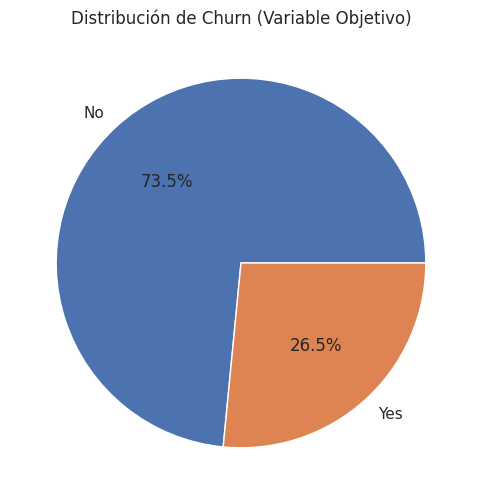

In [11]:
# Configuración de estilo
sns.set(style="whitegrid")

# Visualización de la variable objetivo: Churn
plt.figure(figsize=(6, 6))
plt.pie(Datos['Churn'].value_counts(), labels=Datos['Churn'].value_counts().index, autopct='%1.1f%%')
plt.title('Distribución de Churn (Variable Objetivo)')
plt.show()



**Objetivo:** conocer la proporción de clientes que abandonan y verificar si existe desbalance en la variable objetivo.

**Hallazgo:** la mayoría de los clientes no abandona. La tasa general de churn es cercana al 26,5%.

**Implicancia:** el conjunto presenta desbalance entre las clases. Por esta razón, durante la evaluación de los modelos no será suficiente observar únicamente Accuracy y se dará especial importancia a Recall para detectar clientes que realmente abandonan.


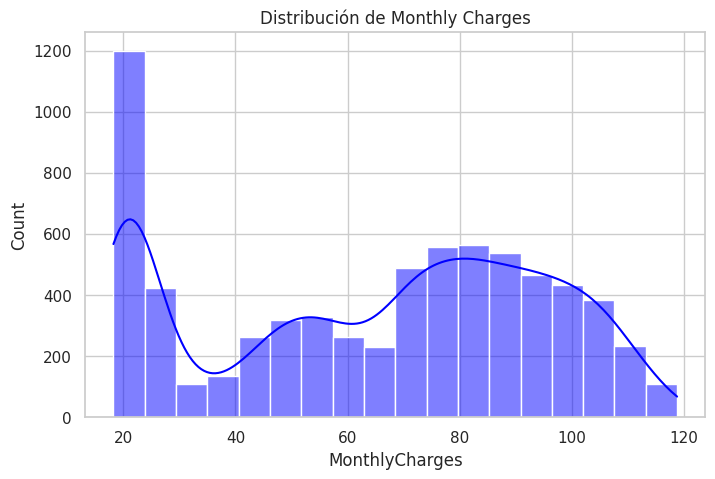

In [12]:
# Histograma de Cargos Mensuales
plt.figure(figsize=(8, 5))
sns.histplot(Datos['MonthlyCharges'], kde=True, color='blue')
plt.title('Distribución de Monthly Charges')
plt.show()

**Objetivo:** analizar la distribución de los cargos mensuales y validar su rango antes del modelamiento.

**Hallazgo:** `MonthlyCharges` presenta valores desde 18,25 hasta 118,75, con una mediana cercana a 70,35. El histograma muestra clientes con cargos bajos y una concentración importante en rangos superiores.

**Implicancia:** la variable presenta suficiente variación para explorar su relación con Churn y será considerada en el proceso de modelamiento.


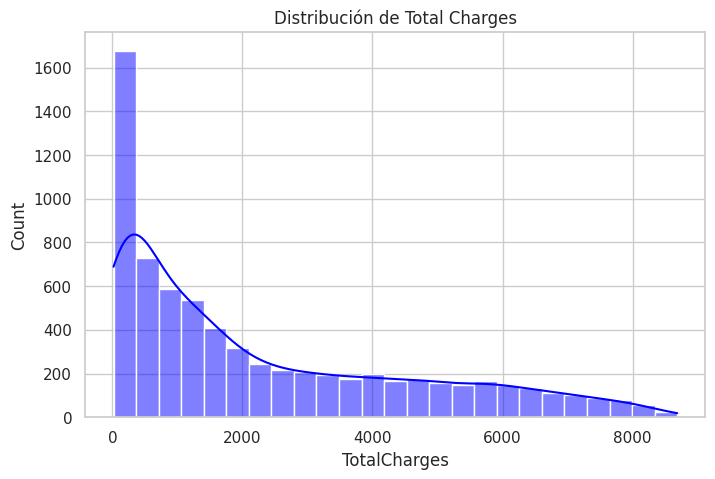

In [13]:
# Histograma de Cargos Totales

plt.figure(figsize=(8, 5))
sns.histplot(Datos['TotalCharges'], kde=True, color='blue')
plt.title('Distribución de Total Charges')
plt.show()

**Objetivo:** observar cómo se distribuye el gasto acumulado de los clientes.

**Hallazgo:** `TotalCharges` presenta una distribución asimétrica, con mayor concentración en valores bajos y una disminución progresiva hacia montos más altos. Esto es coherente con la existencia de clientes nuevos y clientes con mayor permanencia.

**Implicancia:** debido a su relación con la antigüedad, se revisará su correlación con `tenure` antes de utilizar ambas variables en el modelo.


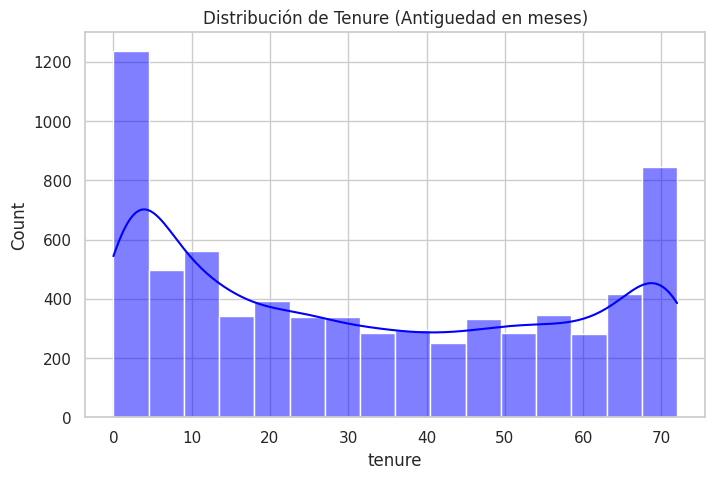

In [14]:
# Histograma de Tenure
plt.figure(figsize=(8, 5))
sns.histplot(Datos['tenure'], kde=True, color='blue')
plt.title('Distribución de Tenure (Antiguedad en meses)')
plt.show()

**Objetivo:** conocer cómo se distribuye la antigüedad de los clientes.

**Hallazgo:** `tenure` contiene clientes desde 0 hasta 72 meses y muestra presencia tanto de clientes recientes como de clientes de larga permanencia.

**Implicancia:** la antigüedad será una variable relevante para estudiar el abandono, especialmente porque los clientes nuevos podrían presentar un comportamiento diferente frente al churn.


## Comparación columna con columna: Análisis Bivariado


### Gráficos de barra bivariados


In [15]:
# Tasas de Churn dentro de cada grupo
def tasa_churn(columna):
    return (
        Datos.groupby(columna)['Churn']
        .apply(lambda x: (x == 'Yes').mean() * 100)
        .round(2)
    )

print("Churn por género:")
print(tasa_churn('gender'))

print("\nChurn por contrato:")
print(tasa_churn('Contract'))

print("\nChurn por facturación electrónica:")
print(tasa_churn('PaperlessBilling'))

print("\nChurn por servicio de internet:")
print(tasa_churn('InternetService'))

print("\nChurn por SeniorCitizen:")
print(tasa_churn('SeniorCitizen'))


Churn por género:
gender
Female    26.92
Male      26.16
Name: Churn, dtype: float64

Churn por contrato:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

Churn por facturación electrónica:
PaperlessBilling
No     16.33
Yes    33.57
Name: Churn, dtype: float64

Churn por servicio de internet:
InternetService
DSL            18.96
Fiber optic    41.89
No              7.40
Name: Churn, dtype: float64

Churn por SeniorCitizen:
SeniorCitizen
0    23.61
1    41.68
Name: Churn, dtype: float64


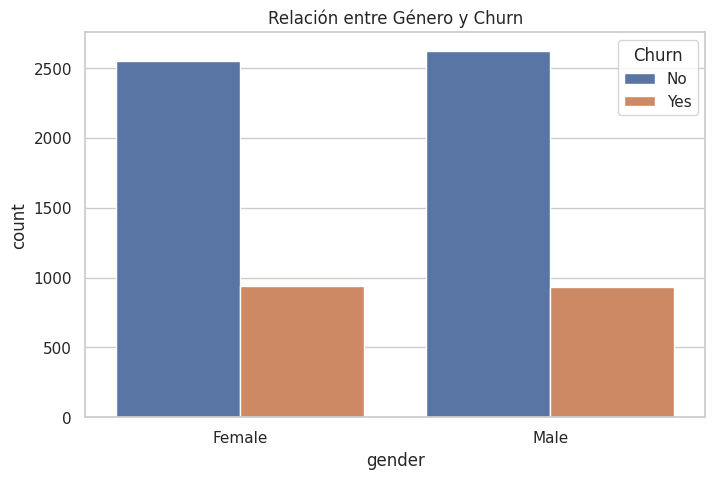

In [16]:
# Género vs Churn
plt.figure(figsize=(8, 5))
sns.countplot(x='gender', hue='Churn', data=Datos)
plt.title('Relación entre Género y Churn')
plt.show()

**Objetivo:** evaluar si el género presenta diferencias relevantes en la tasa de abandono.

**Hallazgo:** las tasas son muy similares entre hombres y mujeres, alrededor de 26%.

**Implicancia:** `gender` no muestra una diferencia importante de churn en este análisis. De todos modos, se mantendrá bajo revisión durante la evaluación ética para comprobar que el modelo no tenga un desempeño desigual entre grupos.


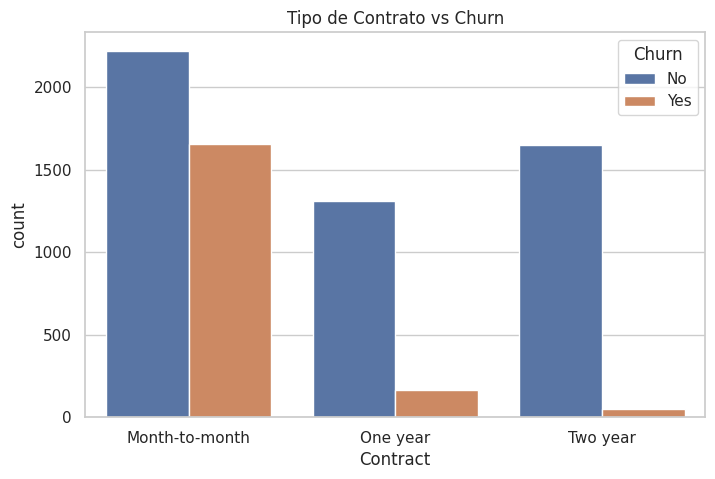

In [17]:
# Contrato vs Churn
plt.figure(figsize=(8, 5))
sns.countplot(x='Contract', hue='Churn', data=Datos)
plt.title('Tipo de Contrato vs Churn')
plt.show()

**Objetivo:** evaluar si el tipo de contrato se relaciona con el abandono, ya que es una variable sobre la cual el negocio puede actuar.

**Hallazgo:** los clientes con contrato `Month-to-month` presentan una tasa de churn cercana al 43%, frente a aproximadamente 11% en contratos de un año y 3% en contratos de dos años.

**Implicancia:** `Contract` será una variable importante para el modelamiento y también respalda una posible estrategia comercial orientada a incentivar contratos de mayor permanencia.


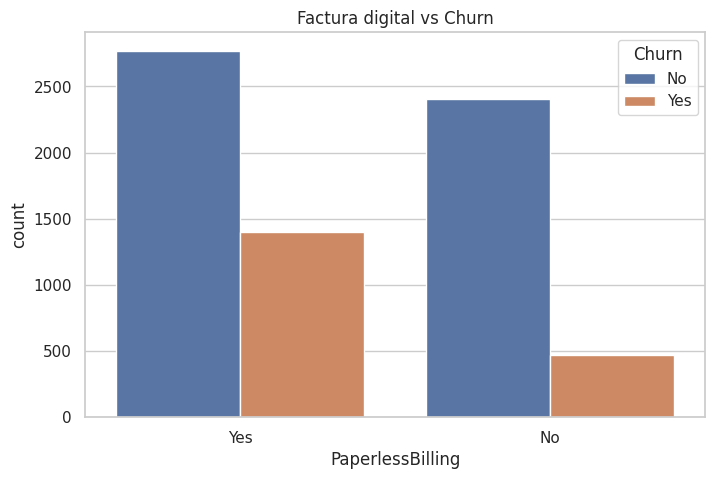

In [18]:
# PaperlessBilling (factura digital) vs Churn
plt.figure(figsize=(8, 5))
sns.countplot(x='PaperlessBilling', hue='Churn', data=Datos)
plt.title('Factura digital vs Churn')
plt.show()

**Objetivo:** analizar si la modalidad de facturación presenta diferencias en el abandono.

**Hallazgo:** los clientes con `PaperlessBilling = Yes` presentan una tasa de churn considerablemente mayor que quienes no utilizan facturación electrónica.

**Implicancia:** esta variable puede aportar información al modelo, aunque el resultado no debe interpretarse como una relación causal sin análisis adicional.


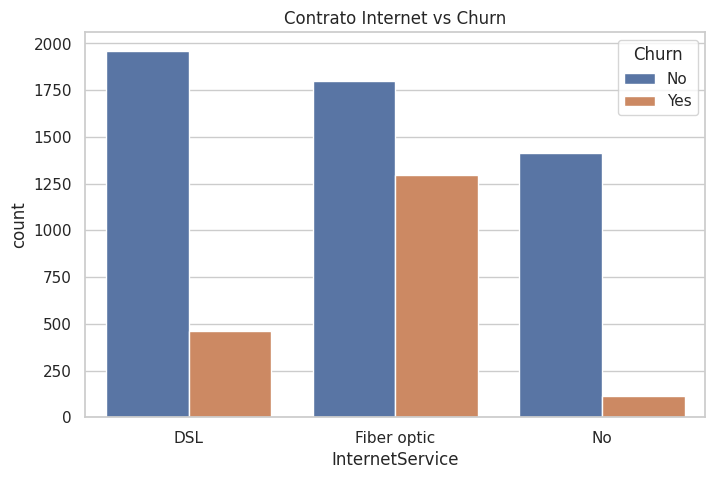

In [19]:
# Contrato internet vs Churn
plt.figure(figsize=(8, 5))
sns.countplot(x='InternetService', hue='Churn', data=Datos)
plt.title('Contrato Internet vs Churn')
plt.show()

**Objetivo:** evaluar si el tipo de servicio de internet se relaciona con el churn.

**Hallazgo:** los clientes con fibra óptica presentan la tasa de abandono más alta entre las categorías de `InternetService`, cercana al 42%.

**Implicancia:** `InternetService` será considerada una variable relevante para el modelamiento y puede orientar una revisión comercial de la experiencia de los clientes de fibra óptica.


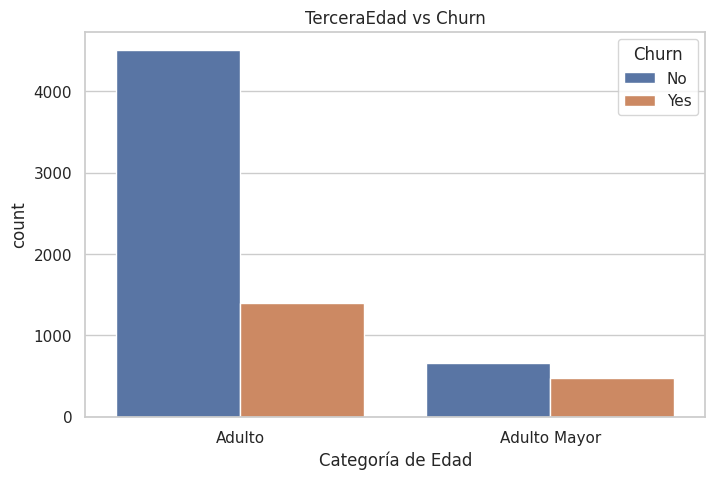

In [20]:
#Tercera Edad vs Churn
plt.figure(figsize=(8, 5))
ax = sns.countplot(x='SeniorCitizen', hue='Churn', data=Datos)

# Asigna los nombres personalizados al eje X porque sino mostrará 1 y 0
ax.set_xticks([0, 1])
ax.set_xticklabels(['Adulto', 'Adulto Mayor'])

plt.title('TerceraEdad vs Churn')
plt.xlabel('Categoría de Edad')
plt.show()

**Objetivo:** comparar la tasa de abandono entre clientes adultos y adultos mayores.

**Hallazgo:** los clientes identificados como `SeniorCitizen = 1` presentan una tasa de churn mayor que el resto de los clientes.

**Implicancia:** la variable podría aportar señal predictiva, pero deberá analizarse con especial cuidado por su carácter sociodemográfico y por los posibles efectos éticos del uso del modelo.


### Boxplots


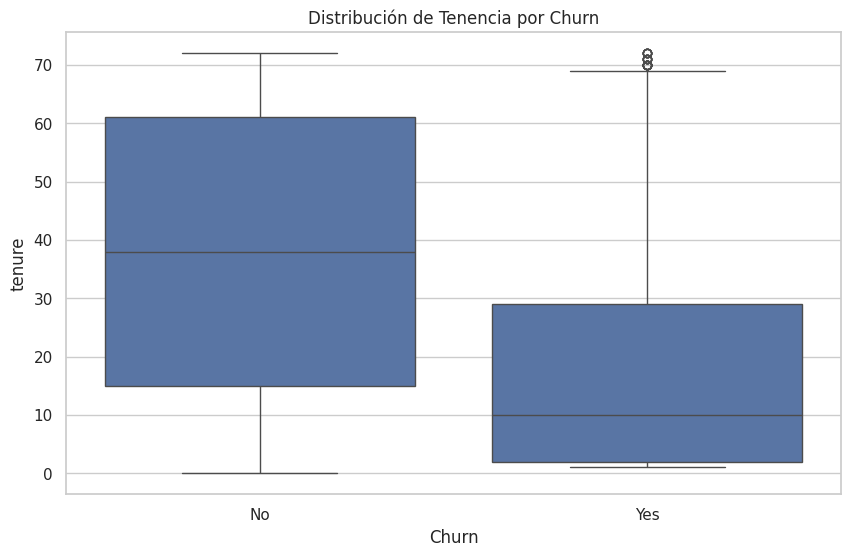

In [21]:
# Tenencia (Tenure) vs Churn
plt.figure(figsize=(10, 6))
sns.boxplot(x='Churn', y='tenure', data=Datos)
plt.title('Distribución de Tenencia por Churn')
plt.show()


**Objetivo:** comparar la antigüedad entre clientes que abandonan y clientes que permanecen.

**Hallazgo:** los clientes que abandonan presentan, en general, una antigüedad menor. La mediana del grupo con churn se encuentra alrededor de 10 meses, mientras que la permanencia de quienes no abandonan es considerablemente mayor.

**Implicancia:** `tenure` aparece como una de las variables más relevantes para explicar el churn y será conservada para el modelamiento.


## Análisis de valores atípicos

Se utiliza el criterio del rango intercuartílico, IQR, sobre las principales variables numéricas continuas. El objetivo es comprobar si existen valores extremos que puedan afectar la interpretación del EDA o el comportamiento de los modelos.


In [22]:
for col in ['tenure', 'MonthlyCharges', 'TotalCharges']:
    q1, q3 = Datos[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    n_out = (
        (Datos[col] < limite_inferior) |
        (Datos[col] > limite_superior)
    ).sum()

    print(f"{col}: {n_out} outliers")


tenure: 0 outliers
MonthlyCharges: 0 outliers
TotalCharges: 0 outliers


**Hallazgo:** bajo el criterio IQR no se detectan valores atípicos en `tenure`, `MonthlyCharges` ni `TotalCharges`.

**Implicancia:** no se requiere eliminar observaciones por outliers en estas variables. Los valores extremos observados se encuentran dentro de rangos válidos del dataset y se conservarán para el modelamiento.


## Visualización de correlación


## Para variables numéricas:


Correlación de variables numéricas con Churn:
tenure           -0.352
TotalCharges     -0.199
SeniorCitizen     0.151
MonthlyCharges    0.193
Name: Churn, dtype: float64


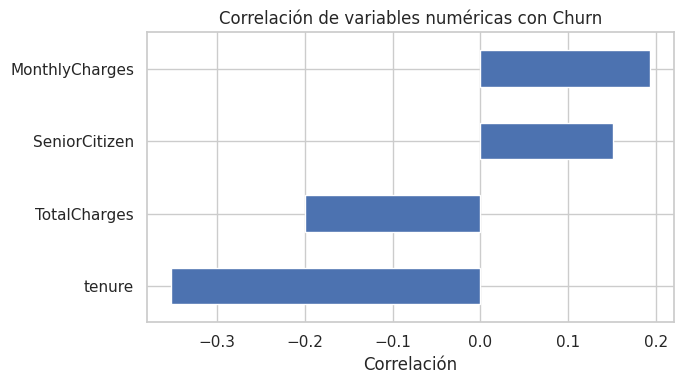

In [23]:
# Crear una copia temporal con las variables numéricas y Churn mapeado
datos_corr = Datos.select_dtypes(include=['number']).copy()
datos_corr['Churn'] = Datos['Churn'].map({'No': 0, 'Yes': 1})

# Correlación de cada variable numérica con Churn
corr_churn = (
    datos_corr.corr()['Churn']
    .drop('Churn')
    .sort_values()
)

print("Correlación de variables numéricas con Churn:")
print(corr_churn.round(3))

# Gráfico más directo para interpretar la relación con la variable objetivo
plt.figure(figsize=(7, 4))
corr_churn.plot(kind='barh')
plt.title('Correlación de variables numéricas con Churn')
plt.xlabel('Correlación')
plt.tight_layout()
plt.show()


**Objetivo:** identificar qué variables numéricas presentan una relación más clara con `Churn` y facilitar su interpretación.

**Hallazgo:** `tenure` presenta la relación inversa más marcada con Churn, cercana a -0,35. Esto indica que los clientes con mayor permanencia tienden a abandonar menos. `MonthlyCharges` y `SeniorCitizen` presentan relaciones positivas más leves, mientras que `TotalCharges` muestra una relación inversa moderada.

**Implicancia:** `tenure` se confirma como una variable relevante para el modelamiento. Las demás variables se conservarán porque una correlación lineal baja no significa necesariamente que no aporten información a modelos capaces de representar relaciones más complejas.


## Para variables categóricas:


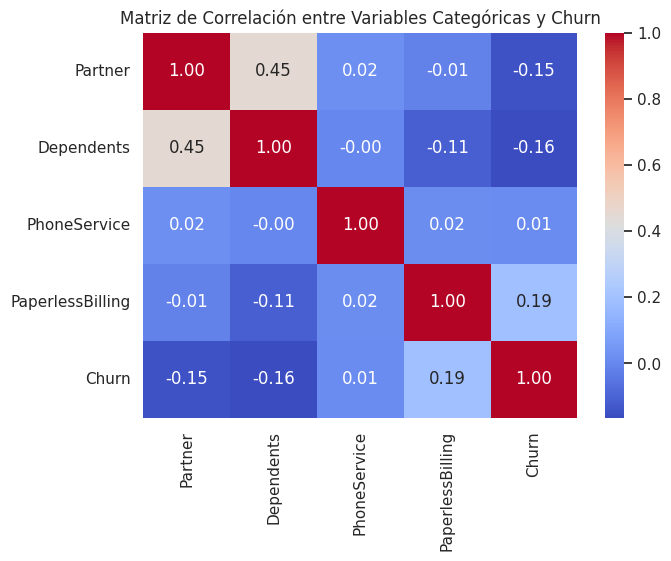

In [24]:
cols_categoricas = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn']

datos_cat_num = Datos[cols_categoricas].map(lambda x: 1 if x == 'Yes' else 0) # 'yes' como 1, sino es 0

# Calculo de la matriz de correlación
corr_cat = datos_cat_num.corr()

# Graficar
plt.figure(figsize=(7, 5))
sns.heatmap(corr_cat, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matriz de Correlación entre Variables Categóricas y Churn')
plt.show()

**Objetivo:** observar relaciones simples entre variables categóricas binarias y Churn.

**Hallazgo:** `Dependents` y `Partner` presentan una relación inversa leve con Churn. También existe una asociación moderada entre ambas variables, lo que es esperable porque representan características relacionadas del hogar.

**Implicancia:** estas relaciones se interpretan como asociaciones y no como causalidad. Las variables se mantendrán para el modelamiento después de su codificación, permitiendo que los algoritmos evalúen su aporte junto con el resto de características.


## Conclusión del EDA

El análisis exploratorio permitió identificar variables especialmente relevantes para comprender el abandono:

* `Contract`: los contratos mes a mes presentan la mayor tasa de churn.
* `tenure`: los clientes que abandonan muestran una permanencia considerablemente menor.
* `InternetService`: los clientes con fibra óptica presentan una tasa de churn más alta.
* `SeniorCitizen`: los adultos mayores presentan una tasa de abandono superior, aunque esta variable requiere especial atención ética.
* `PaperlessBilling`: la facturación electrónica presenta diferencias importantes en la tasa de churn.

Estas variables serán conservadas para el modelamiento junto con el resto de características útiles. Antes de entrenar los modelos se imputarán los valores faltantes, se eliminará `customerID`, se convertirá `Churn` a formato binario y se transformarán las variables categóricas mediante One-Hot Encoding.


## Preparación de los datos para el modelo


Para preparar los datos correctamente debemos revisar que pasa con los 11 valores nulos de TotalCharges.


In [25]:
Datos[Datos['TotalCharges'].isnull()][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


Vemos un tenure de 0, lo que implica que nunca se efectuaron esos cobros y por ello el TotalCharges corresponderá a 0. Se imputan con 0 en lugar de eliminar las filas con el fin de preservar los datos de clientes nuevos y dejar la matriz lista para el modelamiento.


In [26]:
# Imputación de nulos en TotalCharges
Datos['TotalCharges'] = Datos['TotalCharges'].fillna(0)

print("Nulos restantes en TotalCharges:", Datos['TotalCharges'].isnull().sum())

Nulos restantes en TotalCharges: 0


A continuación dropeamos el ID ya que no cumple propósito para el modelo. Así se anonimizan de alguna forma los datos también.


In [27]:
df_model = Datos.drop(columns=['customerID'])

Las variables categóricas todavía se encuentran almacenadas como texto y no pueden ser utilizadas directamente por los algoritmos de scikit-learn. Por ello, se transforma la variable objetivo a formato binario y se aplica One-Hot Encoding a las variables categóricas restantes.


In [28]:
# Variable objetivo a formato binario
df_model['Churn'] = df_model['Churn'].map({'No': 0, 'Yes': 1})

# One-Hot Encoding de variables categóricas
cat_cols = df_model.select_dtypes(include='object').columns

df_model = pd.get_dummies(
    df_model,
    columns=cat_cols,
    drop_first=True
)

print("Dimensiones del dataset preparado:", df_model.shape)
df_model.head()


Dimensiones del dataset preparado: (7043, 31)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,False,True,False,False,True,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,True,False,False,True,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,0,True,False,False,False,True,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,1,False,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False


Con esta transformación, el dataset queda compuesto únicamente por variables numéricas y está listo para ser separado en conjuntos de entrenamiento y prueba. `drop_first=True` evita crear una categoría redundante para cada variable codificada.


# Metodología utilizada (CRISP-DM)


1. **Entendimiento del negocio:** definir los objetivos del proyecto, los KPIs clave y evaluar las necesidades del negocio desde una perspectiva analítica.
2. **Entendimiento de los datos:** recolectar, explorar y analizar la calidad de los datos iniciales para identificar patrones y anomalías relevantes.
3. **Preparación de los datos:** limpiar, imputar nulos, seleccionar variables y transformar los datos a un formato apto para el modelamiento.
4. **Modelado:** seleccionar, entrenar y configurar algoritmos de Machine Learning adecuados al problema de clasificación, además de una técnica no supervisada para descubrir patrones.
5. **Evaluación:** medir el desempeño de los modelos mediante métricas apropiadas y comparar sus resultados con los objetivos del negocio.
6. **Despliegue:** considerar cómo la solución podría integrarse posteriormente en un entorno real, incluyendo documentación, monitoreo y revisión periódica de su desempeño.

CRISP-DM permite mantener el proyecto organizado y relacionar cada etapa técnica con una necesidad concreta del negocio.


# Modelamiento supervisado

En esta etapa pasamos del análisis de los datos a la predicción de `Churn`. Como la variable objetivo tiene dos resultados posibles, cliente que permanece o cliente que abandona, el problema se trabaja como una clasificación binaria.

Para comparar enfoques distintos utilizaremos dos modelos:

* **Regresión Logística:** funciona bien como modelo base porque es sencilla de interpretar y adecuada para clasificación binaria.
* **Random Forest:** permite captar relaciones más complejas entre las variables al combinar varios árboles de decisión.

Como `Churn = 1` aparece menos veces que `Churn = 0`, utilizamos `class_weight='balanced'`. Con esto buscamos que los modelos no se enfoquen solamente en la clase mayoritaria y tengan mayor capacidad para detectar clientes que realmente abandonan.


In [29]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Separar variables predictoras y variable objetivo
X = df_model.drop(columns='Churn')
y = df_model['Churn']

# 80% entrenamiento y 20% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)
print("\nProporción de Churn en entrenamiento:")
print(y_train.value_counts(normalize=True).round(3))
print("\nProporción de Churn en prueba:")
print(y_test.value_counts(normalize=True).round(3))


Entrenamiento: (5634, 30)
Prueba: (1409, 30)

Proporción de Churn en entrenamiento:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

Proporción de Churn en prueba:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


La división estratificada conserva aproximadamente la misma proporción de clientes que abandonan en los conjuntos de entrenamiento y prueba. Esto permite evaluar los modelos sobre una muestra representativa del problema original.


## Modelo 1: Regresión Logística

Comenzamos con Regresión Logística porque es un modelo fácil de interpretar y sirve como una buena referencia inicial.

Antes de entrenarlo estandarizamos las variables, ya que existen diferencias grandes de escala entre características como `TotalCharges`, `MonthlyCharges` y `tenure`.

El escalado se ajusta solamente con los datos de entrenamiento para no utilizar información del conjunto de prueba antes de evaluar el modelo.


In [30]:
# Escalado para Regresión Logística
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

modelo_logistico = LogisticRegression(
    max_iter=2000,
    class_weight='balanced',
    random_state=42
)

modelo_logistico.fit(X_train_scaled, y_train)

pred_logistico = modelo_logistico.predict(X_test_scaled)
prob_logistico = modelo_logistico.predict_proba(X_test_scaled)[:, 1]

print("Matriz de confusión:")
print(confusion_matrix(y_test, pred_logistico))

print("\nReporte de clasificación:")
print(classification_report(y_test, pred_logistico, digits=3))


Matriz de confusión:
[[749 286]
 [ 80 294]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0      0.903     0.724     0.804      1035
           1      0.507     0.786     0.616       374

    accuracy                          0.740      1409
   macro avg      0.705     0.755     0.710      1409
weighted avg      0.798     0.740     0.754      1409



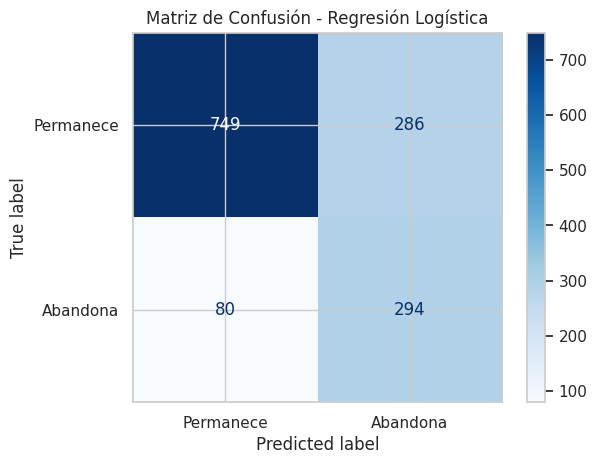

In [31]:
# Matriz de confusión de Regresión Logística
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_logistico,
    display_labels=['Permanece', 'Abandona'],
    cmap='Blues'
)

plt.title('Matriz de Confusión - Regresión Logística')
plt.show()


### Interpretación de la Regresión Logística

La Regresión Logística logra detectar una parte importante de los clientes que realmente abandonan.

La métrica que más nos interesa es el **Recall**, cercano al 79%. En términos simples, de cada 100 clientes que efectivamente se van, el modelo logra identificar aproximadamente 79.

La Precision es menor, por lo que también aparecen clientes marcados como riesgo que finalmente no abandonan. En este caso puede ser un costo aceptable, ya que dejar pasar a un cliente que realmente se irá puede ser más perjudicial que contactar a uno que finalmente permanece.


## Modelo 2: Random Forest

Como segundo modelo utilizamos Random Forest.

Este algoritmo combina varios árboles de decisión y puede representar relaciones que no siempre son lineales. Esto es útil porque el abandono de un cliente probablemente depende de varias características al mismo tiempo, como la antigüedad, el contrato, los cargos y los servicios contratados.

Limitamos la profundidad de los árboles y el tamaño mínimo de las hojas para disminuir el riesgo de sobreajuste.


In [32]:
modelo_rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=3,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

modelo_rf.fit(X_train, y_train)

pred_rf = modelo_rf.predict(X_test)
prob_rf = modelo_rf.predict_proba(X_test)[:, 1]

print("Matriz de confusión:")
print(confusion_matrix(y_test, pred_rf))

print("\nReporte de clasificación:")
print(classification_report(y_test, pred_rf, digits=3))


Matriz de confusión:
[[773 262]
 [ 83 291]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0      0.903     0.747     0.818      1035
           1      0.526     0.778     0.628       374

    accuracy                          0.755      1409
   macro avg      0.715     0.762     0.723      1409
weighted avg      0.803     0.755     0.767      1409



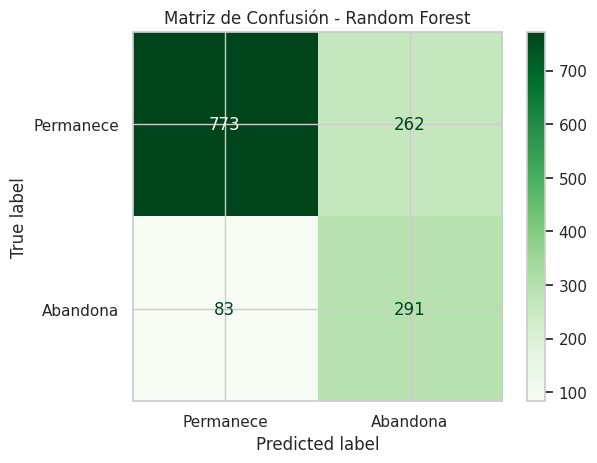

In [33]:
# Matriz de confusión de Random Forest
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_rf,
    display_labels=['Permanece', 'Abandona'],
    cmap='Greens'
)

plt.title('Matriz de Confusión - Random Forest')
plt.show()


### Interpretación de Random Forest

Random Forest obtiene resultados bastante parecidos a la Regresión Logística, pero presenta un equilibrio un poco mejor entre las métricas.

Su Recall se mantiene cercano al 78%, por lo que sigue detectando a la mayoría de los clientes que realmente abandonan. Al mismo tiempo, mejora levemente Precision, F1-score y ROC AUC.

Esto muestra que logra reducir parte de las alertas innecesarias sin perder demasiados casos reales de abandono.


## Comparación de modelos

Para evitar seleccionar un modelo usando una sola métrica, se comparan Accuracy, Precision, Recall, F1-score y ROC AUC. Debido al contexto del negocio, Recall mantiene una importancia especial, ya que un falso negativo corresponde a un cliente que abandona sin ser detectado.


In [34]:
resultados_modelos = pd.DataFrame({
    'Modelo': ['Regresión Logística', 'Random Forest'],
    'Accuracy': [
        accuracy_score(y_test, pred_logistico),
        accuracy_score(y_test, pred_rf)
    ],
    'Precision': [
        precision_score(y_test, pred_logistico),
        precision_score(y_test, pred_rf)
    ],
    'Recall': [
        recall_score(y_test, pred_logistico),
        recall_score(y_test, pred_rf)
    ],
    'F1-score': [
        f1_score(y_test, pred_logistico),
        f1_score(y_test, pred_rf)
    ],
    'ROC AUC': [
        roc_auc_score(y_test, prob_logistico),
        roc_auc_score(y_test, prob_rf)
    ]
})

resultados_modelos.set_index('Modelo').round(3)


,Accuracy,Precision,Recall,F1-score,ROC AUC
Modelo,,,,,
Regresión Logística,0.740,0.507,0.786,0.616,0.841
Random Forest,0.755,0.526,0.778,0.628,0.844


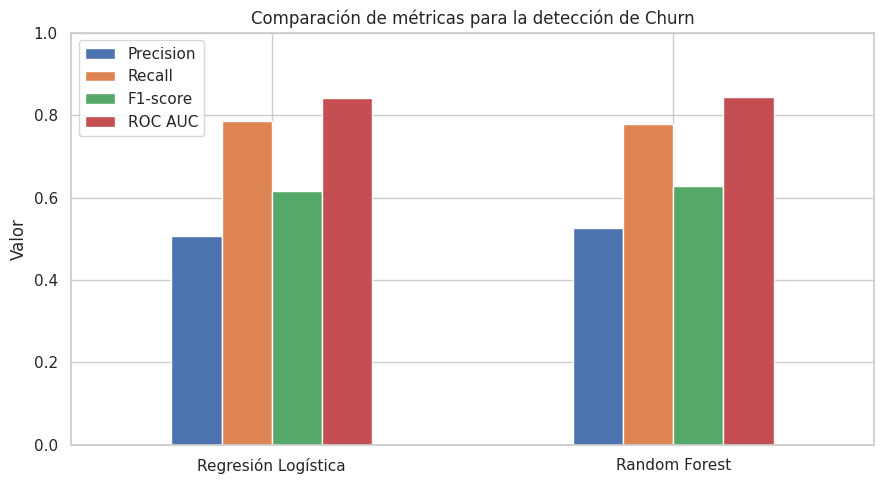

In [35]:
# Comparación visual de las métricas principales
metricas_churn = resultados_modelos.set_index('Modelo')[
    ['Precision', 'Recall', 'F1-score', 'ROC AUC']
]

metricas_churn.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.ylim(0, 1)
plt.title('Comparación de métricas para la detección de Churn')
plt.ylabel('Valor')
plt.xlabel('')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


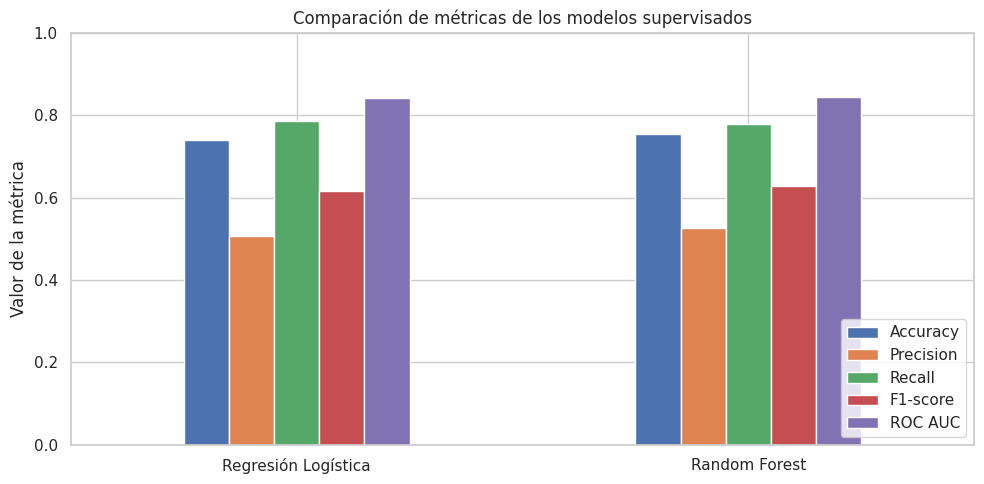

In [36]:
resultados_plot = resultados_modelos.set_index('Modelo')

resultados_plot.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.ylim(0, 1)
plt.title('Comparación de métricas de los modelos supervisados')
plt.ylabel('Valor de la métrica')
plt.xlabel('')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


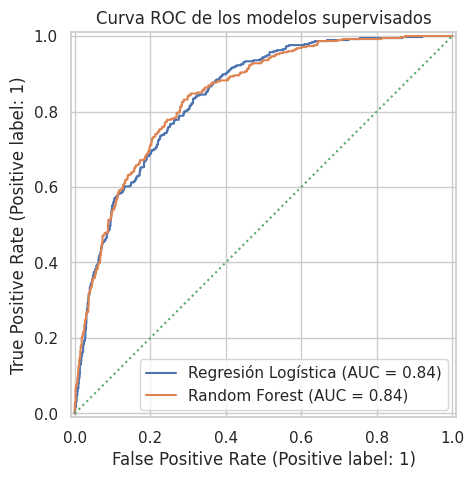

In [37]:
# Curva ROC de ambos modelos
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(8, 5))

RocCurveDisplay.from_predictions(
    y_test,
    prob_logistico,
    name='Regresión Logística',
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test,
    prob_rf,
    name='Random Forest',
    ax=ax
)

ax.plot([0, 1], [0, 1], linestyle=':')
ax.set_title('Curva ROC de los modelos supervisados')
ax.grid(True)
plt.show()


### Selección del modelo

Los dos modelos funcionan de forma bastante similar.

La Regresión Logística obtiene un Recall levemente mayor, mientras que Random Forest presenta un mejor equilibrio general en Accuracy, Precision, F1-score y ROC AUC.

Por este motivo seleccionamos **Random Forest como modelo principal**, manteniendo la Regresión Logística como referencia.

La diferencia entre ambos es pequeña, por lo que esta elección no significa que uno sea perfecto y el otro no sirva. En un escenario real sería necesario volver a evaluarlos con datos nuevos y comprobar que el rendimiento se mantenga con el tiempo.


## Variables más importantes del modelo seleccionado

Random Forest nos permite estimar qué variables utiliza con mayor frecuencia para separar clientes con distinto riesgo de abandono.

Esta importancia no significa que una variable cause el Churn. Solo indica que resulta útil para el modelo al momento de tomar decisiones.

Por eso conviene comparar estas importancias con lo que ya observamos durante el EDA.


tenure                             0.1765
TotalCharges                       0.1294
Contract_Two year                  0.1254
InternetService_Fiber optic        0.0863
MonthlyCharges                     0.0774
PaymentMethod_Electronic check     0.0613
Contract_One year                  0.0453
OnlineSecurity_Yes                 0.0396
TechSupport_No internet service    0.0240
TechSupport_Yes                    0.0235
dtype: float64


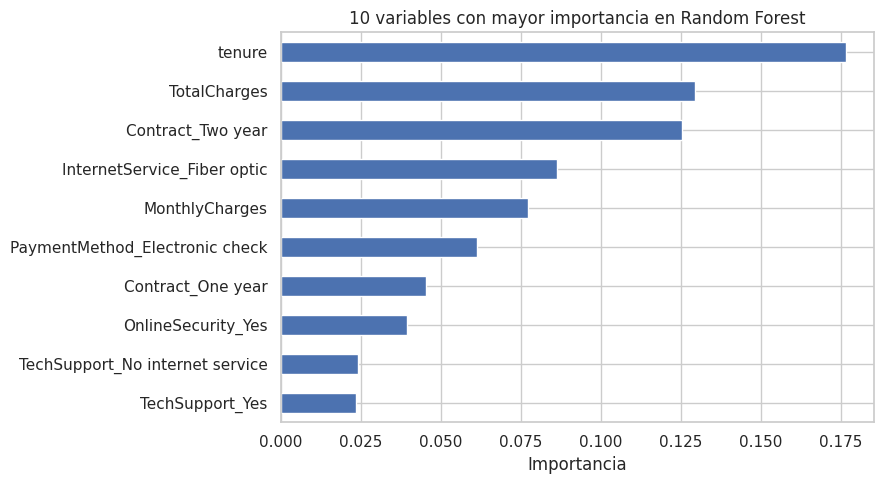

In [38]:
importancias = pd.Series(
    modelo_rf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importancias.head(10).round(4))

plt.figure(figsize=(9, 5))
importancias.head(10).sort_values().plot(kind='barh')
plt.title('10 variables con mayor importancia en Random Forest')
plt.xlabel('Importancia')
plt.tight_layout()
plt.show()


La importancia de variables debe interpretarse junto con el EDA. Si aparecen características como `tenure`, tipo de contrato, cargos mensuales o servicio de internet entre las más relevantes, esto refuerza patrones observados previamente. El EDA informa las decisiones de preparación e interpretación, mientras que el modelo utiliza los datos ya transformados para realizar las predicciones.


# Aprendizaje no supervisado: segmentación con K-Means

Además de predecir qué clientes podrían abandonar, también queremos saber si existen grupos de clientes con características parecidas.

Para esto utilizaremos K-Means con tres variables fáciles de interpretar desde el negocio:

* `tenure`
* `MonthlyCharges`
* `TotalCharges`

No usamos `Churn` para formar los grupos. Primero dejamos que K-Means encuentre segmentos por similitud y después observamos qué nivel de abandono tiene cada uno.

Como K-Means trabaja con distancias, primero escalamos las variables para evitar que `TotalCharges` tenga más peso solo por manejar números más grandes.


In [39]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

variables_cluster = ['tenure', 'MonthlyCharges', 'TotalCharges']

X_cluster = Datos[variables_cluster].copy()

scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

inercias = []
silhouettes = []
rango_k = range(2, 9)

for k in rango_k:
    modelo_k = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo_k.fit_predict(X_cluster_scaled)

    inercias.append(modelo_k.inertia_)
    silhouettes.append(
        silhouette_score(X_cluster_scaled, etiquetas)
    )

evaluacion_k = pd.DataFrame({
    'K': list(rango_k),
    'Inercia': inercias,
    'Silhouette': silhouettes
})

evaluacion_k.round(3)


,K,Inercia,Silhouette
0,2,9712.112,0.480
1,3,6186.187,0.451
2,4,4148.483,0.472
3,5,3111.402,0.444
4,6,2562.928,0.440
5,7,2204.448,0.450
6,8,1863.214,0.425


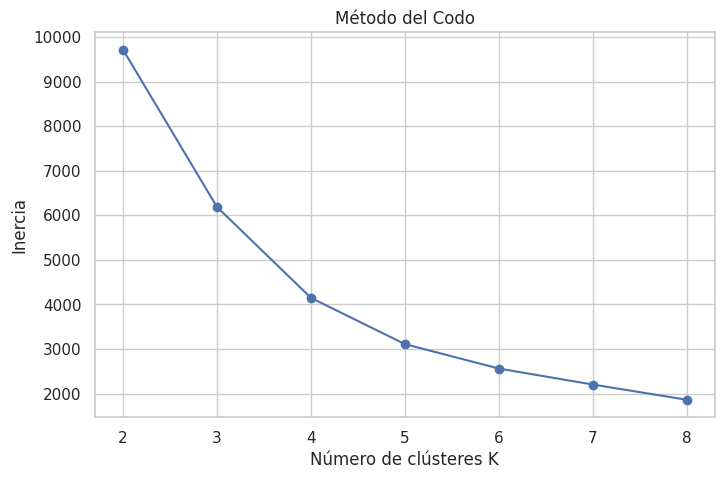

In [40]:
plt.figure(figsize=(8, 5))
plt.plot(
    list(rango_k),
    inercias,
    marker='o'
)
plt.title('Método del Codo')
plt.xlabel('Número de clústeres K')
plt.ylabel('Inercia')
plt.grid(True)
plt.show()


El método del codo muestra una disminución fuerte de la inercia durante los primeros valores de K y luego mejoras progresivamente menores. Se selecciona **K = 4** porque mantiene una separación razonable y permite obtener segmentos suficientemente distintos para ser interpretados desde el negocio.

La métrica Silhouette se utiliza como apoyo y no como única regla de decisión, ya que el objetivo también requiere que los segmentos resultantes sean comprensibles y accionables.


In [41]:
k_optimo = 4

modelo_kmeans = KMeans(
    n_clusters=k_optimo,
    random_state=42,
    n_init=10
)

Datos['Cluster'] = modelo_kmeans.fit_predict(X_cluster_scaled)

perfil_clusters = (
    Datos.groupby('Cluster')[variables_cluster]
    .mean()
    .round(2)
)

perfil_clusters['Clientes'] = (
    Datos['Cluster']
    .value_counts()
    .sort_index()
)

perfil_clusters['Churn_%'] = (
    Datos.groupby('Cluster')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .round(2)
)

perfil_clusters


,tenure,MonthlyCharges,TotalCharges,Clientes,Churn_%
Cluster,,,,,
0,10.21,31.78,302.15,1703,24.66
1,59.53,93.31,5548.65,1904,15.39
2,15.42,80.78,1251.17,2276,48.24
3,53.57,34.91,1835.62,1160,5.00


## Interpretación de los clústeres

Los cuatro clústeres muestran perfiles de clientes distintos.

* **Clúster 0:** clientes relativamente nuevos, con cargos mensuales bajos y gasto acumulado reducido.
* **Clúster 1:** clientes con mayor antigüedad, cargos mensuales altos y gasto acumulado elevado.
* **Clúster 2:** clientes con poca antigüedad y cargos mensuales altos. Este grupo presenta la mayor tasa de Churn.
* **Clúster 3:** clientes con mayor permanencia y cargos mensuales bajos. Es el grupo con menor abandono.

El **Clúster 2** es el más interesante desde el punto de vista comercial, porque combina poca permanencia con cargos altos y concentra la mayor tasa de fuga.

Una posible acción sería revisar de forma temprana la experiencia de estos clientes y ofrecer beneficios o alternativas de permanencia antes de que decidan abandonar.


# Aspectos Éticos, Sesgos y Privacidad de Datos


### 1. Privacidad de los Datos y Anonimización

* El dataset utiliza un identificador alfanumérico (`customerID`) que no revela directamente información como RUT, nombres, direcciones o números telefónicos.
* Para el modelamiento, la columna `customerID` se descarta para que el modelo aprenda de patrones de comportamiento, servicios, facturación y contrato, y no de identificadores personales.
* Se aplica el principio de minimización de datos, utilizando solo las variables necesarias para los objetivos analíticos del proyecto.

### 2. Marco normativo y estándares de privacidad

De acuerdo con la retroalimentación recibida, el proyecto debe considerar como referencia:

* **Ley 19.628 de Chile:** regula la protección de la vida privada y el tratamiento de datos personales.
* **Ley 21.719 de Chile:** refuerza principios asociados a licitud, finalidad, proporcionalidad y seguridad en el tratamiento de datos personales.
* **GDPR como referencia internacional:** considera principios como minimización de datos, limitación de la finalidad y transparencia frente a decisiones automatizadas.

Dentro del proyecto se aplican medidas como la eliminación del identificador, el uso de variables necesarias para el análisis y la documentación de la finalidad del modelo.

### 3. Evaluación de Sesgos

* **Análisis de Género:** en el EDA se observa una tasa de churn similar entre hombres y mujeres. Aun así, durante la evaluación de los modelos se deberá revisar que métricas como Recall no presenten diferencias importantes entre subgrupos.
* **Variables sociodemográficas:** `SeniorCitizen` presenta diferencias en churn y podría aportar información predictiva, pero su utilización requiere revisar posibles efectos de discriminación o desempeño desigual.
* **Prevención de discriminación:** el modelo se utilizará para apoyar acciones de retención y no para restringir servicios o aplicar penalizaciones. Un desempeño menor en ciertos grupos podría provocar que algunos clientes reciban menos oportunidades de retención.

### 4. Consideraciones Éticas en la Aplicación Comercial

* **Transparencia en retención:** las predicciones deben utilizarse para ofrecer incentivos, mejoras de servicio o planes de fidelización, evitando prácticas abusivas.
* **Explicabilidad:** se priorizará poder explicar las variables que influyen en las predicciones para que la empresa pueda comprender las razones detrás de la clasificación de riesgo.
* **Supervisión humana:** las predicciones no deberían utilizarse como una decisión automática definitiva, sino como apoyo para que el negocio evalúe acciones de retención de forma responsable.


## Auditoría de desempeño por subgrupos

Además de evaluar el desempeño global del modelo, se revisa el Recall de Random Forest según `gender` y `SeniorCitizen`. El objetivo es comprobar si la capacidad de detectar clientes que realmente abandonan cambia de manera importante entre subgrupos.

Esta revisión no demuestra por sí sola la ausencia de sesgo, pero permite detectar diferencias que deberían investigarse antes de una implementación real.


In [42]:
# Auditoría de Recall por subgrupos usando el conjunto de prueba
auditoria = Datos.loc[X_test.index, ['gender', 'SeniorCitizen']].copy()

auditoria['Real'] = y_test.values
auditoria['Predicho'] = pred_rf

def recall_por_grupo(df, columna):
    resultados = []

    for grupo, datos_grupo in df.groupby(columna):
        recall = recall_score(
            datos_grupo['Real'],
            datos_grupo['Predicho'],
            zero_division=0
        )

        resultados.append({
            columna: grupo,
            'Clientes_prueba': len(datos_grupo),
            'Churn_reales': int(datos_grupo['Real'].sum()),
            'Recall': round(recall, 3)
        })

    return pd.DataFrame(resultados)

print("Recall por género:")
display(recall_por_grupo(auditoria, 'gender'))

print("\nRecall por SeniorCitizen:")
display(recall_por_grupo(auditoria, 'SeniorCitizen'))


Recall por género:


,gender,Clientes_prueba,Churn_reales,Recall
0,Female,687,193,0.751
1,Male,722,181,0.807



Recall por SeniorCitizen:


,SeniorCitizen,Clientes_prueba,Churn_reales,Recall
0,0,1187,276,0.750
1,1,222,98,0.857


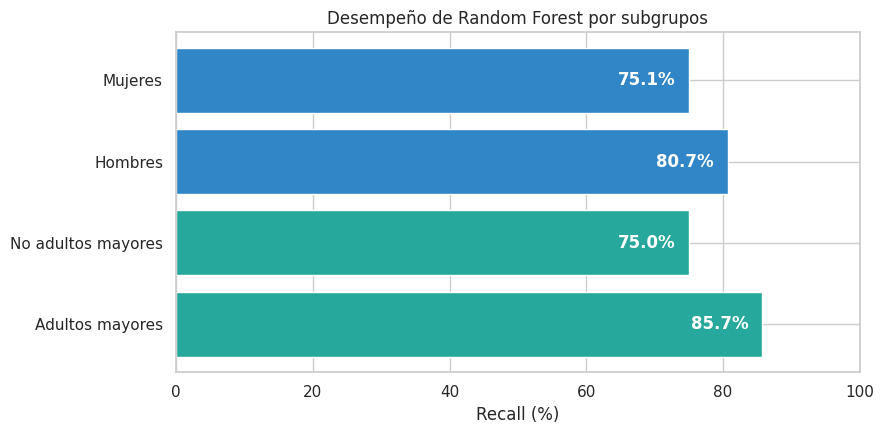

In [43]:

# Gráfico de Recall por subgrupos

tabla_genero = recall_por_grupo(auditoria, 'gender')
tabla_senior = recall_por_grupo(auditoria, 'SeniorCitizen')

tabla_genero['Grupo'] = tabla_genero['gender'].map({
    'Female': 'Mujeres',
    'Male': 'Hombres'
})

tabla_senior['Grupo'] = tabla_senior['SeniorCitizen'].map({
    0: 'No adultos mayores',
    1: 'Adultos mayores'
})

datos_grafico = pd.concat([
    tabla_genero[['Grupo', 'Recall']],
    tabla_senior[['Grupo', 'Recall']]
], ignore_index=True)

plt.figure(figsize=(9, 4.5))

barras = plt.barh(
    datos_grafico['Grupo'],
    datos_grafico['Recall'] * 100,
    color=['#3186C7', '#3186C7', '#27A89C', '#27A89C']
)

plt.gca().invert_yaxis()
plt.xlim(0, 100)

for barra in barras:
    valor = barra.get_width()
    plt.text(
        valor - 2,
        barra.get_y() + barra.get_height() / 2,
        f'{valor:.1f}%',
        ha='right',
        va='center',
        color='white',
        fontweight='bold'
    )

plt.xlabel('Recall (%)')
plt.title('Desempeño de Random Forest por subgrupos')
plt.tight_layout()
plt.show()


### Interpretación de la auditoría

Al analizar el Recall de Random Forest por género, observamos que el modelo logra detectar el 75,1% de los abandonos en mujeres y el 80,7% en hombres. Esto muestra una diferencia de 5,6 puntos porcentuales.

En el caso de SeniorCitizen, los clientes clasificados como adultos mayores presentan un Recall de 85,7%, mientras que el resto alcanza un 75,0%.

Estos resultados muestran que el modelo no tiene exactamente el mismo desempeño en todos los grupos. Sin embargo, las diferencias no demuestran por sí solas la existencia de discriminación, especialmente porque la cantidad de casos evaluados varía entre grupos.

Por este motivo, antes de utilizar el modelo en una empresa real, sería importante seguir revisando estas métricas y comprobar que las decisiones comerciales sean justas para todos los clientes.


# Conclusiones y recomendaciones

A lo largo del proyecto pasamos desde entender el problema de negocio hasta construir y comparar modelos de Machine Learning.

Los resultados muestran que el abandono no ocurre de forma aleatoria. Se concentra especialmente en clientes con poca antigüedad, contratos mes a mes y ciertos perfiles de servicio y facturación.

Random Forest fue el modelo con mejor equilibrio general, mientras que la Regresión Logística logró un Recall levemente mayor. Ambos pueden ser útiles como herramientas de apoyo para priorizar clientes en riesgo.

La segmentación con K-Means también permitió identificar un grupo especialmente sensible, formado por clientes con baja permanencia y cargos mensuales altos.

A partir de esto, una estrategia razonable sería enfocar acciones de retención en clientes nuevos, especialmente aquellos con contratos mensuales y cargos elevados.

El modelo no debería utilizarse como una decisión automática. Su función es apoyar al negocio con información adicional y siempre debería complementarse con revisión humana y monitoreo periódico.


## Limitaciones del análisis

Los resultados se obtienen a partir de un dataset histórico y representan asociaciones observadas en esos datos. No permiten afirmar causalidad entre las variables y el abandono.

Además, el desempeño de los modelos puede cambiar frente a nuevos clientes o cambios comerciales. Por esta razón, una implementación real requeriría validación periódica, ajuste de parámetros, monitoreo de deriva de datos y revisión continua de métricas de desempeño y equidad.
